<a href="https://colab.research.google.com/github/jmitchell3636/Marketing-Expenditure-and-Revenue-Analysis/blob/main/Jake_Mitchell_Prompt_3_Evaluating_Marketing_Spend_and_ROI_through_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Marketing Expenditure and Revenue Analysis

**Task**: Determine the relationship between marketing expenditures and revenue to evaluate the return on investment (ROI) for different campaigns.

### Data Extraction
- Load data from a **CSV file** containing monthly marketing expenditures across various channels (e.g., social media, email, TV ads) and corresponding revenue figures.

### Pre-Processing
- Handle missing data and consider creating additional features like **"marketing efficiency"**, which measures the revenue generated per unit of marketing spend.

$$
\text{Marketing Efficiency} = \frac{\text{Revenue}}{\text{Total Marketing Spend}}
$$


### Data Summary
- Generate summary statistics to understand distributions and correlations.
- **Visualization**:
    - Create histograms of numerical variables.
    - Visually examine the pattern in revenue by date, use the **datetime** library if necessary to convert the date variable to the appropriate date type.
    - Calculate pairwise correlations and create a heatmap of the values
    - Generate a scatterplot matrix to show pairwise scatterplots.

### Statistical Modeling
- Use **statsmodels** to build a **simple linear regression model** with total marketing spend as the independent variable and revenue as the dependent variable.
- Extend to **multiple linear regression** to assess the impact of each channel separately.
- Interpret coefficients to identify which marketing channels have the highest ROI and make recommendations for optimizing spending.

In [1]:
import pandas as pd
import requests
from io import StringIO

orig_url="https://drive.google.com/file/d/1KJl5lpA7F65T2YD1y-iKv9gZ6Y3eZv_s/view?usp=drive_link"

file_id = orig_url.split('/')[-2]
dwn_url='https://drive.google.com/uc?export=download&id=' + file_id
url = requests.get(dwn_url).text
csv_raw = StringIO(url)
mkt_data = pd.read_csv(csv_raw)
mkt_data.head()

,Date,Social Media,Email,TV Ads,Revenue,Total Marketing Spend
0,1/1/25,7492.35,2540.83,13999.37,233001.96,24032.55
1,1/2/25,7077.84,2478.07,14202.37,225488.50,22730.65
2,1/3/25,7179.93,3058.99,13529.26,212942.01,22500.59
3,1/4/25,8029.77,3056.84,12783.35,216024.57,23110.97
4,1/5/25,7819.45,3176.71,11860.85,208448.77,22077.36


In [2]:
df = pd.DataFrame(mkt_data)
# converting data to DataFrame

In [3]:
# Handling missing values
# Using the medain in order to fill the missing values
df['Social Media'] = df['Social Media'].fillna(df['Social Media'].median())
df['Email'] = df['Email'].fillna(df['Email'].median())
df['TV Ads']  = df['TV Ads'].fillna(df['TV Ads'].median())
df['Revenue'] = df['Revenue'].fillna(df['Revenue'].median())



Creating a new variable for marketing efficiency

In [4]:
def marketing_efficieny(row):
    Revenue = row['Revenue']
    Total_Marketing_Spend = row['Total Marketing Spend']

    marketing_efficieny = Revenue / Total_Marketing_Spend
    return marketing_efficieny

df['Marketing Efficiency'] = df.apply(marketing_efficieny, axis = 1)
df.head()

,Date,Social Media,Email,TV Ads,Revenue,Total Marketing Spend,Marketing Efficiency
0,1/1/25,7492.35,2540.83,13999.37,233001.96,24032.55,9.695266
1,1/2/25,7077.84,2478.07,14202.37,225488.50,22730.65,9.920020
2,1/3/25,7179.93,3058.99,13529.26,212942.01,22500.59,9.463841
3,1/4/25,8029.77,3056.84,12783.35,216024.57,23110.97,9.347274
4,1/5/25,7819.45,3176.71,11860.85,208448.77,22077.36,9.441743


In [5]:
#Creating a statistical summary
df.describe()

,Social Media,Email,TV Ads,Revenue,Total Marketing Spend,Marketing Efficiency
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,6310.966400,2977.666700,12695.823400,199648.193500,20561.076600,9.692096
std,987.390799,499.608249,1873.946229,27242.688374,2317.003943,0.455649
min,4633.340000,1715.350000,9757.470000,156371.110000,16624.070000,8.219064
25%,5473.357500,2666.677500,10954.145000,174500.167500,18559.485000,9.364173
50%,6388.330000,3052.160000,12783.060000,199205.795000,20672.000000,9.651206
75%,7177.522500,3356.270000,14349.225000,222709.075000,22615.152500,10.028158
max,8029.770000,3964.240000,16159.310000,249931.400000,24237.040000,11.926762


**Social Media**


*  The mean amount spent on social media marketing is 6,310.87, with a standard deviation of 987.39
*  The minimum spent was 4,633.34 and the maximum spent was 8,029.77



**Email**


*  The mean amount spent on email marketing was 2,977.67, with a standard deviation of 499.60
*   The minimum spent was 1,715.35 and the maximum spent was 3,964.24



**TV Ads**


*   The mean amount spent on TV ads was 12,695.82 with the standard ddeviation being 1,873.95
*   The minimum spent was 9,757.47 and the maximum was 16,159.31




**Revenue**


*   The mean revenue for one day was 199,648.19 with the standard deviation being 27,242.69
* The minimum revenue for one day was 156,371.11 and the maximum was 249,931.40



**Total Marketing Spend**


*   The mean total marketing spend in a day was 20,561.07 with the standard deviation being 2,317
* The minimum total marketing spend in one day was 16,624.07 and the maximum was 24,237.04



**Marketing Efficiency**


*   The mean marketing efficiency was 9.69 with a standard deviation of 0.456
*   The minimum was 8.22 and the maximum was 11.93



Based on the results above, there are no outliers that should impact analysis, and none of the data appears to be skewed in such a way it would impact analysis.

In [6]:

#Converting to datetime
#Help from internet for this code. Tried creating variables for each month, but found this code worked best

from datetime import datetime

df['Date'] =pd.to_datetime(df['Date'])

df['Month'] = df['Date'].apply(lambda d: datetime(d.year, d.month, 1))
monthlytotal = df.groupby('Month')['Total Marketing Spend'].sum()

df['Month'] = df['Date'].apply(lambda d: datetime(d.year, d.month, 1))
monthlyrev = df.groupby('Month')['Revenue'].sum()


/tmp/ipykernel_5282/3234584922.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] =pd.to_datetime(df['Date'])


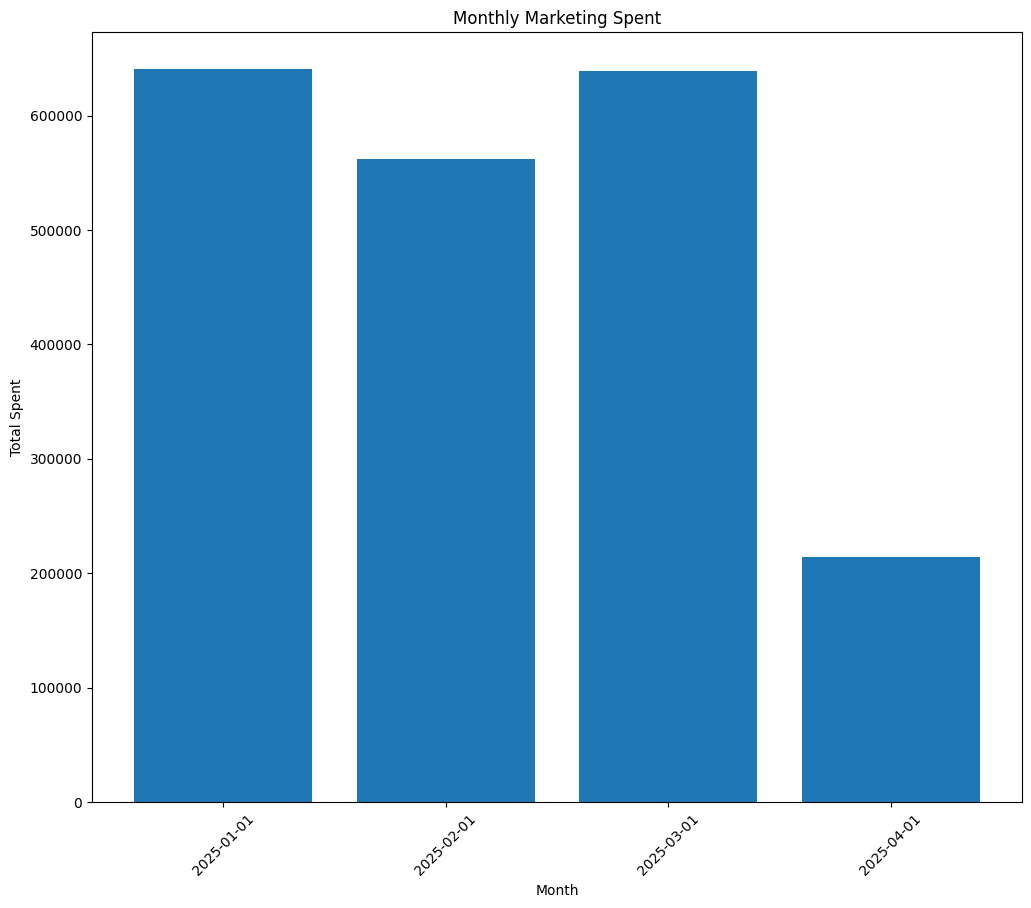

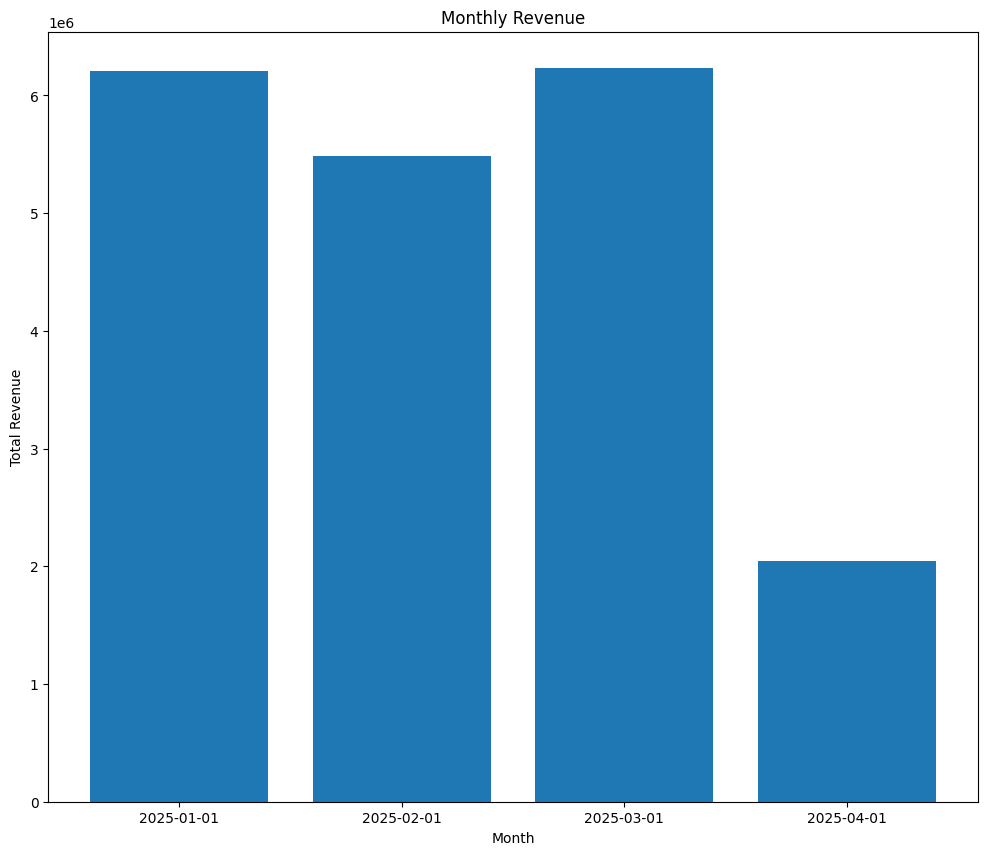

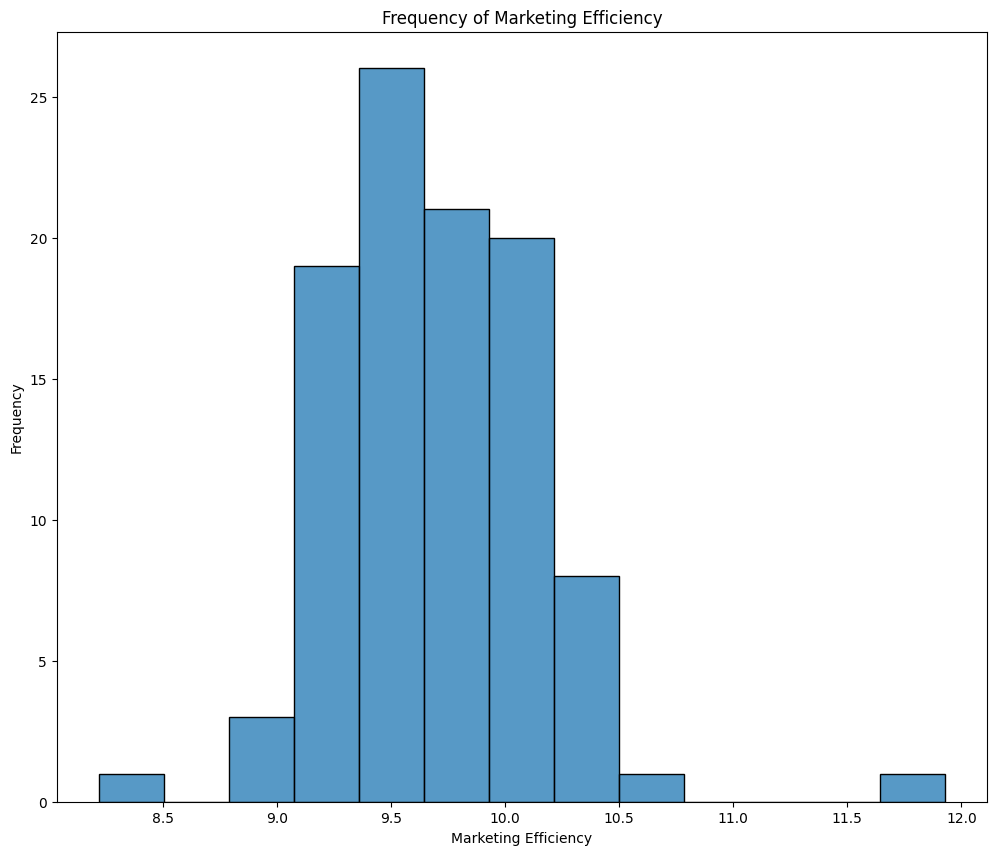

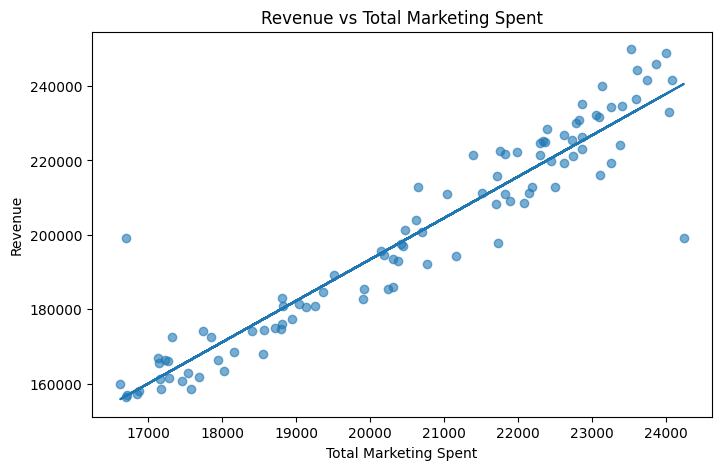

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#Creating bar chart for total monthly marketing spend
plt.figure(figsize =(12,10))
plt.bar(monthlytotal.index.astype(str), monthlytotal.values)
plt.title('Monthly Marketing Spent')
plt.xlabel('Month')
plt.ylabel('Total Spent')
plt.xticks(rotation=45)

#Creating bar chart for total monthly revenue
plt.figure(figsize =(12,10))
plt.bar(monthlyrev.index.astype(str), monthlyrev.values)
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Total Revenue')

#Creating histogram for Marketing Efficieny
plt.figure(figsize =(12,10))
sns.histplot(df['Marketing Efficiency'], kde=False)
plt.title('Frequency of Marketing Efficiency')
plt.xlabel('Marketing Efficiency')
plt.ylabel('Frequency')

#Scatter plot for revenue and spending
plt.figure(figsize =(8,5))
m, b= np.polyfit(df['Total Marketing Spend'], df['Revenue'], 1)
plt.scatter(df['Total Marketing Spend'],df['Revenue'], alpha =0.6)
plt.xlabel("Total Marketing Spent")
plt.ylabel("Revenue")
plt.title("Revenue vs Total Marketing Spent")
plt.plot(df['Total Marketing Spend'], m*df['Total Marketing Spend']+b)
#internet and AI search returned some code for regression line

plt.show()



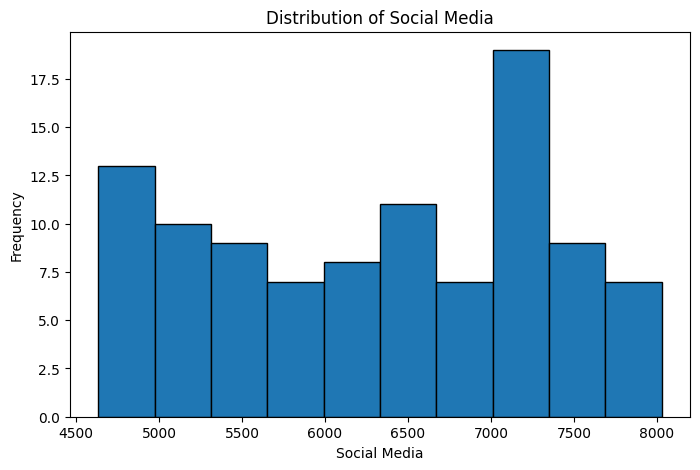

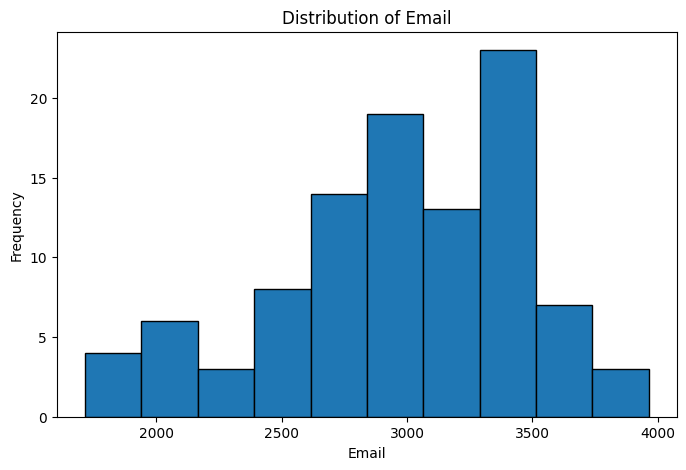

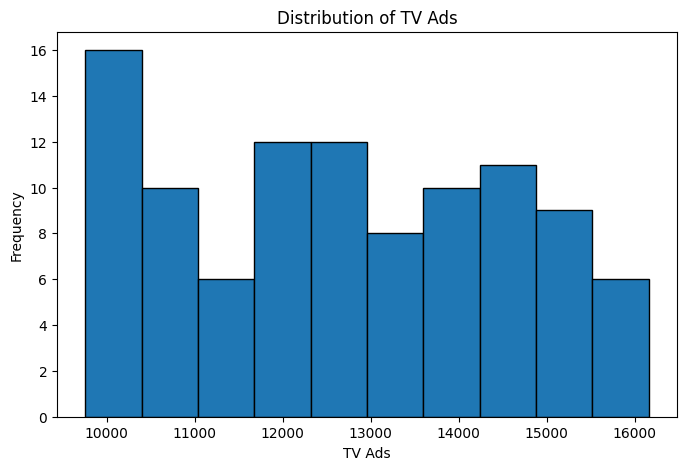

In [8]:
# Created histograms showing the distribution of spending on the different marketing campaigns

numerical_vars = ['Social Media','Email','TV Ads']

for var in numerical_vars:
    plt.figure(figsize=(8,5))
    plt.hist(df[var].dropna(),bins=10, edgecolor='black')
    plt.title(f'Distribution of {var}')
    plt.xlabel(var)
    plt.ylabel('Frequency')
    plt.show()

In [9]:
#Calculating the pairwise correlations and creating the heatmap of values

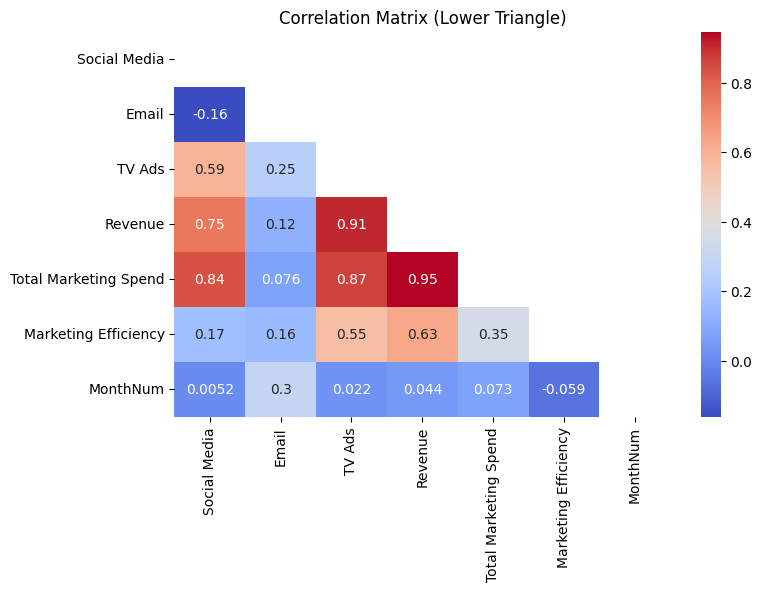

In [10]:
df['MonthNum'] = df['Date'].dt.month
# Had to turn the date variable into a numeric value in order to run the correlation matrix

correlationmatrix= df[['Social Media','Email','TV Ads','Revenue','Total Marketing Spend','Marketing Efficiency','MonthNum']].corr()
mask= np.triu(np.ones_like(correlationmatrix, dtype=bool))

plt.figure(figsize=(8,5))
sns.heatmap(correlationmatrix, annot=True, cmap= 'coolwarm', mask=mask)
plt.title('Correlation Matrix (Lower Triangle)')
plt.show()

In [11]:
# Using statsmodel to build a simple linear regression model with total marketing spend as the IV and revenue as the DV
import statsmodels.api as sm

y=df['Revenue']
X = df['Total Marketing Spend']

X = sm.add_constant(X)

model= sm.OLS(y,X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                Revenue   R-squared:                       0.898
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     861.0
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.45e-50
Time:                        15:15:53   Log-Likelihood:                -1048.6
No. Observations:                 100   AIC:                             2101.
Df Residuals:                      98   BIC:                             2106.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                 -2.942e+

In [12]:
# Now building a multiple linear regression to asses the impact of each channel seperately
L =df['Revenue']
W = df[['Social Media','Email','TV Ads']]

W = sm.add_constant(W)

model= sm.OLS(L,W).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                Revenue   R-squared:                       0.902
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                     295.8
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.36e-48
Time:                        15:15:53   Log-Likelihood:                -1046.3
No. Observations:                 100   AIC:                             2101.
Df Residuals:                      96   BIC:                             2111.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.156e+04   8356.504      1.383   

**R-squared**

An R squared of 0.902 means that approximately 90.2% of the variability in Revenue is explained by the spending in Social Media, Email, and TV Ad marketing.



**Significant Coefficients**

***Social Media***

For every 1 unit increase in Social Media marketing spending, Revenue increases by 8.91, holding other variables constant.
- This suggests a strong positive relationship between Social Media marketing spending and revenue.

***Email***

For every 1 unit increase in Email marketing
spending, Revenue decreases by 0.586, holding other variables constant.
- The estimate is negative, but it is not statistically significant (see the p-value below), so the data does not show that Email spending changes revenue.

***TV Ads***

For every 1 unit increase in TV Ads spending, Revenue increases by 10.53, holding other variables constant.
- This suggests a strong positive relationship between TV Ad spending and revenue.


**P-value**

***Social Media***
The P-value for Social Media marketing spending is 0.000, meaning it is highly significant meaning there is strong evidence that social media marketing spending results in higher revenue.


***Email***
The P-value for Email marketing spending is 0.766, meaning it is not significant. There is no reliable evidence that Email marketing spending raises or lowers revenue.


***TV Ads***
The P-value for TV Ads marketing spending is 0.000, meaning it is highly significant meaning there is strong evidence that TV Ads marketing spending results in higher revenue.

**Business Recommendations**


*   Focus on Social Media and TV Ads marketing. Spending money on these marketing channels has shown to be correlated to increased revenue.
*   Cut Email marketing first. Email spending showed no measurable effect on revenue, so that budget is better spent on Social Media and TV Ads.

